# Urban Traffic Flow, Congestion Management & Mobility Optimization
## Bangalore traffic analysis — project notebook

**Important data limitation:** the supplied dataset has a `Date` field but no time-of-day field, explicit road type, zone, commercial-hub distance, event identifier, or population/demographic data. Analyses requiring those fields are marked as unavailable or use clearly labelled proxies. Do not interpret proxy metrics as measured travel delay or causal effects.

## 1. Introduction
The project studies traffic volume, speed, congestion, capacity utilization, travel-time index, incidents, weather, roadwork, public transport usage, signal compliance, parking, and pedestrian/cyclist counts. Results describe the supplied dataset, not necessarily all Bangalore roads.

## 2. Data loading

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path(r"C:\Users\Hp\Banglore_traffic_Dataset.csv")
if not DATA_PATH.exists():
    # If the notebook is run from another directory, update DATA_PATH to the CSV location.
    raise FileNotFoundError(f"Place {DATA_PATH.name} beside this notebook or update DATA_PATH.")
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
df.columns = [c.strip().lower().replace("/", "_").replace(" ", "_") for c in df.columns]
df["date"] = pd.to_datetime(df["date"], errors="coerce")
print("Shape:", df.shape)
display(df.head())
df.info()
display(df.describe(include="all").T)

Shape: (8936, 16)


,date,area_name,road_intersection_name,traffic_volume,average_speed,travel_time_index,congestion_level,road_capacity_utilization,incident_reports,environmental_impact,public_transport_usage,traffic_signal_compliance,parking_usage,pedestrian_and_cyclist_count,weather_conditions,roadwork_and_construction_activity
0,2022-01-01,Indiranagar,100 Feet Road,50590,50.230299,1.500000,100.000000,100.000000,0,151.180,70.632330,84.044600,85.403629,111,Clear,No
1,2022-01-01,Indiranagar,CMH Road,30825,29.377125,1.500000,100.000000,100.000000,1,111.650,41.924899,91.407038,59.983689,100,Clear,No
2,2022-01-01,Whitefield,Marathahalli Bridge,7399,54.474398,1.039069,28.347994,36.396525,0,64.798,44.662384,61.375541,95.466020,189,Clear,No
3,2022-01-01,Koramangala,Sony World Junction,60874,43.817610,1.500000,100.000000,100.000000,1,171.748,32.773123,75.547092,63.567452,111,Clear,No
4,2022-01-01,Koramangala,Sarjapur Road,57292,41.116763,1.500000,100.000000,100.000000,3,164.584,35.092601,64.634762,93.155171,104,Clear,No


<class 'pandas.DataFrame'>
RangeIndex: 8936 entries, 0 to 8935
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   date                                8936 non-null   datetime64[us]
 1   area_name                           8936 non-null   str           
 2   road_intersection_name              8936 non-null   str           
 3   traffic_volume                      8936 non-null   int64         
 4   average_speed                       8936 non-null   float64       
 5   travel_time_index                   8936 non-null   float64       
 6   congestion_level                    8936 non-null   float64       
 7   road_capacity_utilization           8936 non-null   float64       
 8   incident_reports                    8936 non-null   int64         
 9   environmental_impact                8936 non-null   float64       
 10  public_transport_usage             

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,8936,NaN,NaN,NaN,2023-04-22 05:25:11.548791,2022-01-01 00:00:00,2022-08-26 00:00:00,2023-04-24 00:00:00,2023-12-17 06:00:00,2024-08-09 00:00:00,NaN
area_name,8936,8,Indiranagar,1720,NaN,NaN,NaN,NaN,NaN,NaN,NaN
road_intersection_name,8936,16,100 Feet Road,860,NaN,NaN,NaN,NaN,NaN,NaN,NaN
traffic_volume,8936.0,NaN,NaN,NaN,29236.04812,4233.0,19413.0,27600.0,38058.5,72039.0,13001.808801
average_speed,8936.0,NaN,NaN,NaN,39.447427,20.0,31.775825,39.199368,46.644517,89.790843,10.707244
travel_time_index,8936.0,NaN,NaN,NaN,1.375554,1.000039,1.242459,1.5,1.5,1.5,0.165319
congestion_level,8936.0,NaN,NaN,NaN,80.818041,5.160279,64.292905,92.389018,100.0,100.0,23.533182
road_capacity_utilization,8936.0,NaN,NaN,NaN,92.029215,18.739771,97.35499,100.0,100.0,100.0,16.583341
incident_reports,8936.0,NaN,NaN,NaN,1.570389,0.0,0.0,1.0,2.0,10.0,1.420047
environmental_impact,8936.0,NaN,NaN,NaN,108.472096,58.466,88.826,105.2,126.117,194.078,26.003618


## 3. Data understanding — Tasks 1–2

In [2]:
print("Columns:", df.columns.tolist())
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Unique dates:", df["date"].nunique())
print("Areas:", df["area_name"].nunique(), sorted(df["area_name"].dropna().unique()))
print("Road/intersection names:", df["road_intersection_name"].nunique())
display(df.groupby(["area_name", "road_intersection_name"]).size().rename("records").sort_values().to_frame())

Columns: ['date', 'area_name', 'road_intersection_name', 'traffic_volume', 'average_speed', 'travel_time_index', 'congestion_level', 'road_capacity_utilization', 'incident_reports', 'environmental_impact', 'public_transport_usage', 'traffic_signal_compliance', 'parking_usage', 'pedestrian_and_cyclist_count', 'weather_conditions', 'roadwork_and_construction_activity']
Date range: 2022-01-01 00:00:00 to 2024-08-09 00:00:00
Unique dates: 952
Areas: 8 ['Electronic City', 'Hebbal', 'Indiranagar', 'Jayanagar', 'Koramangala', 'M.G. Road', 'Whitefield', 'Yeshwanthpur']
Road/intersection names: 16


records
area_name       road_intersection_name         
Electronic City Silk Board Junction         275
                Hosur Road                  277
Yeshwanthpur    Tumkur Road                 361
                Yeshwanthpur Circle         373
Whitefield      ITPL Main Road              450
Hebbal          Hebbal Flyover              474
                Ballari Road                476
Whitefield      Marathahalli Bridge         492
Jayanagar       Jayanagar 4th Block         580
                South End Circle            593
Koramangala     Sarjapur Road               680
                Sony World Junction         684
M.G. Road       Trinity Circle              742
                Anil Kumble Circle          759
Indiranagar     100 Feet Road               860
                CMH Road                    860

**Interpretation guide:** the natural observation key available is `(date, area_name, road_intersection_name)`. It is not a guaranteed globally unique road-segment ID, but it is the best available composite key in these files. There is no time-of-day, lane ID, sensor ID, coordinates, or explicit road-segment identifier, so the data cannot distinguish multiple observations at the same road within one day unless other fields differ.

## 4. Data cleaning and analytical view — Tasks 3–5

In [3]:
print("Missing values before cleaning:")
display(df.isna().sum().to_frame("missing"))
print("Exact duplicate rows:", df.duplicated().sum())
key = ["date", "area_name", "road_intersection_name"]
print("Duplicate observation keys:", df.duplicated(key).sum())

# Preserve raw data; parse date; normalize column names; remove only invalid date rows.
before_rows = len(df)
df = df.dropna(subset=["date"]).copy()
# Do not impute values unless missingness is found; this dataset has no missing values in the supplied file.
numeric_cols = df.select_dtypes(include="number").columns
print("Rows before/after date validation:", before_rows, len(df))
print("Missing after date validation:", int(df.isna().sum().sum()))
print("Coverage:", df["date"].min(), df["date"].max())
print("Records per date distribution:")
display(df.groupby("date").size().value_counts().sort_index().rename_axis("records_per_date").to_frame("number_of_dates"))

Missing values before cleaning:


,missing
date,0
area_name,0
road_intersection_name,0
traffic_volume,0
average_speed,0
travel_time_index,0
congestion_level,0
road_capacity_utilization,0
incident_reports,0
environmental_impact,0


Exact duplicate rows: 0
Duplicate observation keys: 0
Rows before/after date validation: 8936 8936
Missing after date validation: 0
Coverage: 2022-01-01 00:00:00 2024-08-09 00:00:00
Records per date distribution:


,number_of_dates
records_per_date,
4,4
5,11
6,23
7,95
8,152
9,213
10,199
11,156
12,71


**Preparation impact:** no missing values or exact duplicate rows were detected in the supplied CSV, so numeric imputation and row deduplication are not needed. Record counts vary by date, however, so daily averages may be affected by changing coverage. The correct response is to report coverage and avoid treating missing road-date combinations as zero traffic.

## 5. Data validation and quality audit — Task 6

In [4]:
print("Negative traffic volumes:", int((df["traffic_volume"] < 0).sum()))
print("Non-positive speeds:", int((df["average_speed"] <= 0).sum()))
print("Congestion outside 0–100:", int((~df["congestion_level"].between(0, 100)).sum()))
print("Capacity utilization outside 0–100:", int((~df["road_capacity_utilization"].between(0, 100)).sum()))
print("Duplicate full rows:", int(df.duplicated().sum()))
print("Duplicate date-area-road keys:", int(df.duplicated(key).sum()))
print("Categorical values:")
for col in ["weather_conditions", "roadwork_and_construction_activity"]:
    print(col, df[col].value_counts(dropna=False).to_dict())

Negative traffic volumes: 0
Non-positive speeds: 0
Congestion outside 0–100: 0
Capacity utilization outside 0–100: 0
Duplicate full rows: 0
Duplicate date-area-road keys: 0
Categorical values:
weather_conditions {'Clear': 5426, 'Overcast': 1296, 'Fog': 959, 'Rain': 827, 'Windy': 428}
roadwork_and_construction_activity {'No': 8054, 'Yes': 882}


## 6. Chronological review — Task 7

In [5]:
df["day_name"] = df["date"].dt.day_name()
df["day_of_week"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year
df["is_weekend"] = df["day_of_week"] >= 5
daily_counts = df.groupby("date").size()
expected_dates = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
missing_calendar_dates = expected_dates.difference(pd.DatetimeIndex(df["date"].dropna().unique()))
print("Calendar dates with no records:", len(missing_calendar_dates))
print("First missing dates:", list(missing_calendar_dates[:15]))
display(df.groupby("day_name")["traffic_volume"].agg(["count","mean","median"]).reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]))

Calendar dates with no records: 0
First missing dates: []


,count,mean,median
day_name,,,
Monday,1296,29510.237654,28004.5
Tuesday,1309,28911.255157,27122.0
Wednesday,1266,29697.560821,28008.5
Thursday,1250,29530.357600,27643.0
Friday,1253,28842.780527,27430.0
Saturday,1290,29062.983721,27258.0
Sunday,1272,29105.277516,27916.5


There is no hour/time column, so morning/evening rush-hour claims cannot be tested from this dataset. Date-level weekday/weekend comparisons are possible, but changing daily road coverage must be considered.

## 7. Volume, speed and congestion consistency — Task 8

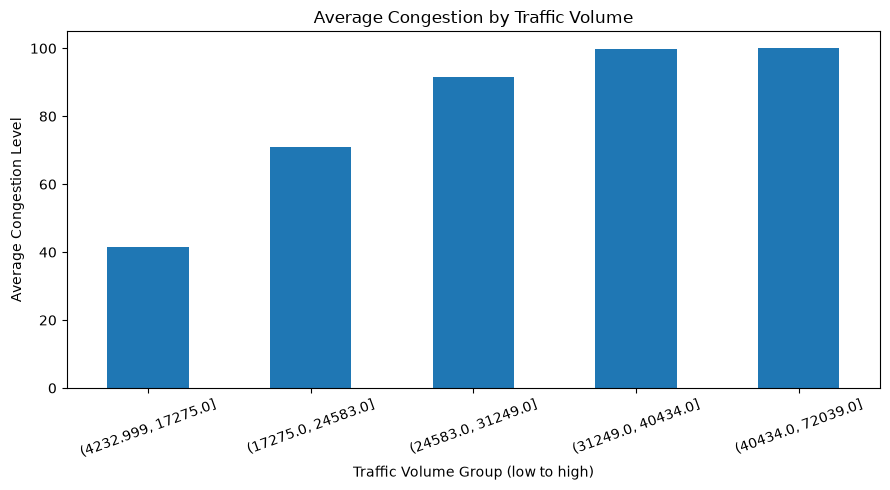

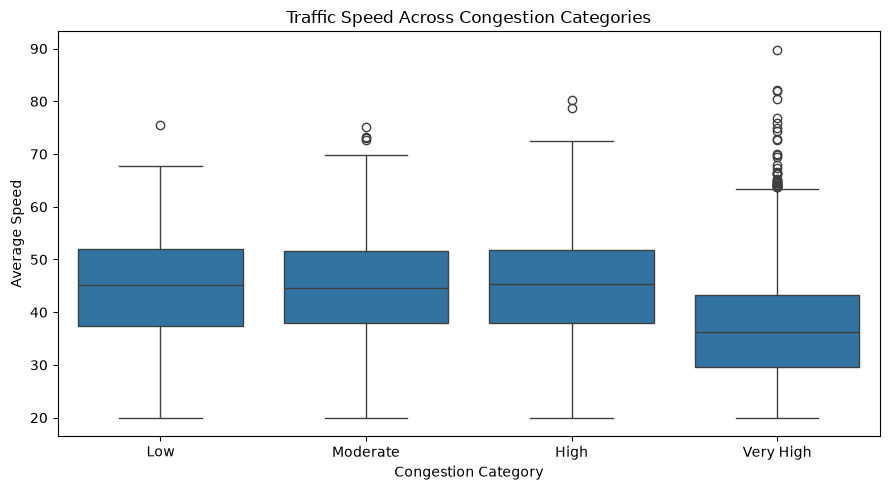

In [6]:
# Task 8: Clearer traffic consistency plots

# Graph 1: Average congestion by traffic-volume group
df["volume_group_plot"] = pd.qcut(
    df["traffic_volume"], q=5, duplicates="drop"
)

volume_summary = df.groupby(
    "volume_group_plot", observed=True
)["congestion_level"].mean()

plt.figure(figsize=(9, 5))
volume_summary.plot(kind="bar", rot=20)
plt.title("Average Congestion by Traffic Volume")
plt.xlabel("Traffic Volume Group (low to high)")
plt.ylabel("Average Congestion Level")
plt.tight_layout()
plt.show()

# Graph 2: Speed distribution by congestion category
df["congestion_category_plot"] = pd.cut(
    df["congestion_level"],
    bins=[-0.01, 25, 50, 75, 100.01],
    labels=["Low", "Moderate", "High", "Very High"]
)

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=df,
    x="congestion_category_plot",
    y="average_speed"
)
plt.title("Traffic Speed Across Congestion Categories")
plt.xlabel("Congestion Category")
plt.ylabel("Average Speed")
plt.tight_layout()
plt.show()

## 8. Abnormal patterns — Task 9

In [7]:
vol_mean, vol_std = df["traffic_volume"].mean(), df["traffic_volume"].std()
df["volume_z_score"] = (df["traffic_volume"] - vol_mean) / vol_std
volume_anomalies = df.loc[df["volume_z_score"].abs() >= 3].sort_values("volume_z_score", ascending=False)
display(volume_anomalies[["date","area_name","road_intersection_name","traffic_volume","volume_z_score","congestion_level"]].head(30))

,date,area_name,road_intersection_name,traffic_volume,volume_z_score,congestion_level
6072,2023-10-11,Koramangala,Sony World Junction,72039,3.292077,100.0
2002,2022-08-01,Koramangala,Sarjapur Road,71610,3.259081,100.0
1653,2022-06-26,Koramangala,Sony World Junction,69874,3.125561,100.0
4010,2023-03-05,Koramangala,Sarjapur Road,69494,3.096335,100.0
2314,2022-09-03,Koramangala,Sony World Junction,69407,3.089643,100.0
587,2022-03-04,Koramangala,Sarjapur Road,69293,3.080875,100.0
2814,2022-10-26,Koramangala,Sony World Junction,69272,3.079260,100.0
8898,2024-08-06,Koramangala,Sony World Junction,69158,3.070492,100.0
5392,2023-08-02,Koramangala,Sony World Junction,68275,3.002579,100.0


## 9. Feature engineering — Task 10

In [8]:
df["high_congestion_flag"] = (df["congestion_level"] >= df["congestion_level"].quantile(.75)).astype(int)
df["high_capacity_flag"] = (df["road_capacity_utilization"] >= 90).astype(int)
df["delay_index_proxy"] = np.where(df["average_speed"] > 0, df["traffic_volume"] / df["average_speed"], np.nan)
df["utilization_balance_proxy"] = 100 - df["road_capacity_utilization"]
df = df.sort_values(["area_name","road_intersection_name","date"]).copy()
df["flow_stability_7obs"] = df.groupby(["area_name","road_intersection_name"])["average_speed"].transform(
    lambda s: s.rolling(7, min_periods=3).std()
)
display(df[["high_congestion_flag","high_capacity_flag","delay_index_proxy","utilization_balance_proxy","flow_stability_7obs"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
high_congestion_flag,8936.0,0.434646,0.495738,0.000000,0.000000,0.000000,1.000000,1.000000
high_capacity_flag,8936.0,0.782117,0.412830,0.000000,1.000000,1.000000,1.000000,1.000000
delay_index_proxy,8936.0,837.758230,511.280145,72.805255,429.869894,743.509455,1134.082341,3276.750000
utilization_balance_proxy,8936.0,7.970785,16.583341,0.000000,0.000000,0.000000,2.645010,81.260229
flow_stability_7obs,8904.0,10.067450,2.867896,1.787807,7.992200,9.894045,11.929745,23.313102


**Rationale:** flags identify high congestion and near/at-capacity observations; `delay_index_proxy = traffic_volume / average_speed` is only a relative proxy, not minutes of delay. Seven-observation rolling speed standard deviation measures variation across available observations, not necessarily seven consecutive calendar days.

## 10. KPI framework — Task 11

In [9]:
overall_kpis = pd.Series({
    "mean_speed": df["average_speed"].mean(),
    "mean_congestion": df["congestion_level"].mean(),
    "mean_travel_time_index": df["travel_time_index"].mean(),
    "peak_congestion_severity_proxy": df.loc[df["high_congestion_flag"].eq(1), "congestion_level"].mean(),
    "high_congestion_share_pct": 100 * df["high_congestion_flag"].mean(),
    "high_capacity_share_pct": 100 * df["high_capacity_flag"].mean(),
    "mean_delay_index_proxy": df["delay_index_proxy"].mean(),
    "mean_capacity_utilization": df["road_capacity_utilization"].mean(),
    "mean_signal_compliance": df["traffic_signal_compliance"].mean(),
})
display(overall_kpis.to_frame("value").round(3))

,value
mean_speed,39.447
mean_congestion,80.818
mean_travel_time_index,1.376
peak_congestion_severity_proxy,100.000
high_congestion_share_pct,43.465
high_capacity_share_pct,78.212
mean_delay_index_proxy,837.758
mean_capacity_utilization,92.029
mean_signal_compliance,79.950


Formula notes:
- Average speed = mean of `average_speed`.
- Peak congestion severity proxy = mean congestion among observations at or above the dataset's 75th congestion percentile (not a time-of-day peak).
- Off-peak utilization cannot be isolated without time-of-day data.
- Reliability proxy = proportion of observations below the 75th-percentile congestion threshold; this is a dataset-relative measure, not a formal travel-time reliability index.
- Network resilience cannot be measured causally without incident start/end and recovery timestamps; incident counts and variation can be described as proxies only.

## 11. Location and time profiles — Task 12

In [10]:
location_profile = df.groupby("area_name").agg(
    observations=("congestion_level","size"),
    mean_volume=("traffic_volume","mean"),
    mean_speed=("average_speed","mean"),
    mean_congestion=("congestion_level","mean"),
    mean_tti=("travel_time_index","mean"),
    mean_capacity_utilization=("road_capacity_utilization","mean"),
    incident_mean=("incident_reports","mean")
).sort_values("mean_congestion", ascending=False)
display(location_profile.round(2))
road_profile = df.groupby("road_intersection_name").agg(
    observations=("congestion_level","size"),
    mean_volume=("traffic_volume","mean"),
    mean_speed=("average_speed","mean"),
    mean_congestion=("congestion_level","mean"),
    mean_tti=("travel_time_index","mean")
).sort_values("mean_congestion", ascending=False)
display(road_profile.round(2))

,observations,mean_volume,mean_speed,mean_congestion,mean_tti,mean_capacity_utilization,incident_mean
area_name,,,,,,,
Koramangala,1364,40832.25,36.06,93.99,1.47,97.43,1.85
M.G. Road,1501,35300.43,37.54,90.58,1.44,96.55,1.86
Indiranagar,1720,32284.39,38.64,87.64,1.40,95.76,1.78
Hebbal,950,26533.23,40.15,80.09,1.37,92.72,1.57
Jayanagar,1173,24601.33,39.79,77.00,1.36,91.52,1.48
Whitefield,942,21295.13,42.14,69.05,1.29,86.88,1.28
Yeshwanthpur,734,18931.55,43.45,62.37,1.26,82.40,1.08
Electronic City,552,16346.64,43.66,54.45,1.23,76.26,0.78


,observations,mean_volume,mean_speed,mean_congestion,mean_tti
road_intersection_name,,,,,
Sony World Junction,684,41470.80,35.98,94.13,1.47
Sarjapur Road,680,40189.95,36.15,93.85,1.47
Anil Kumble Circle,759,35251.83,37.40,90.78,1.44
Trinity Circle,742,35350.14,37.68,90.37,1.44
CMH Road,860,32611.92,38.86,88.18,1.41
100 Feet Road,860,31956.85,38.43,87.11,1.40
Hebbal Flyover,474,26794.92,40.34,80.66,1.37
Ballari Road,476,26272.64,39.96,79.51,1.36
South End Circle,593,24704.12,39.44,77.28,1.36


## 12. Area influence and equity — Task 13 and Task 18

In [11]:
# The dataset contains area names but no zone, commercial-hub distance, or demographic/population fields.
display(df.groupby("area_name").agg(
    mean_congestion=("congestion_level","mean"),
    median_congestion=("congestion_level","median"),
    mean_speed=("average_speed","mean"),
    mean_volume=("traffic_volume","mean"),
    mean_public_transport_usage=("public_transport_usage","mean"),
    observations=("date","size")
).sort_values("mean_congestion", ascending=False).round(2))

,mean_congestion,median_congestion,mean_speed,mean_volume,mean_public_transport_usage,observations
area_name,,,,,,
Koramangala,93.99,100.00,36.06,40832.25,45.90,1364
M.G. Road,90.58,100.00,37.54,35300.43,45.44,1501
Indiranagar,87.64,100.00,38.64,32284.39,44.92,1720
Hebbal,80.09,91.03,40.15,26533.23,44.44,950
Jayanagar,77.00,83.05,39.79,24601.33,43.98,1173
Whitefield,69.05,70.79,42.14,21295.13,44.59,942
Yeshwanthpur,62.37,61.73,43.45,18931.55,46.13,734
Electronic City,54.45,53.42,43.66,16346.64,45.58,552


Equity limitation: area-level congestion comparisons are possible, but disproportionate effects on population groups cannot be established without demographic, accessibility, income, or trip-purpose data. Do not make population-equity claims from area names alone.

## 13. Trend analysis — Task 14

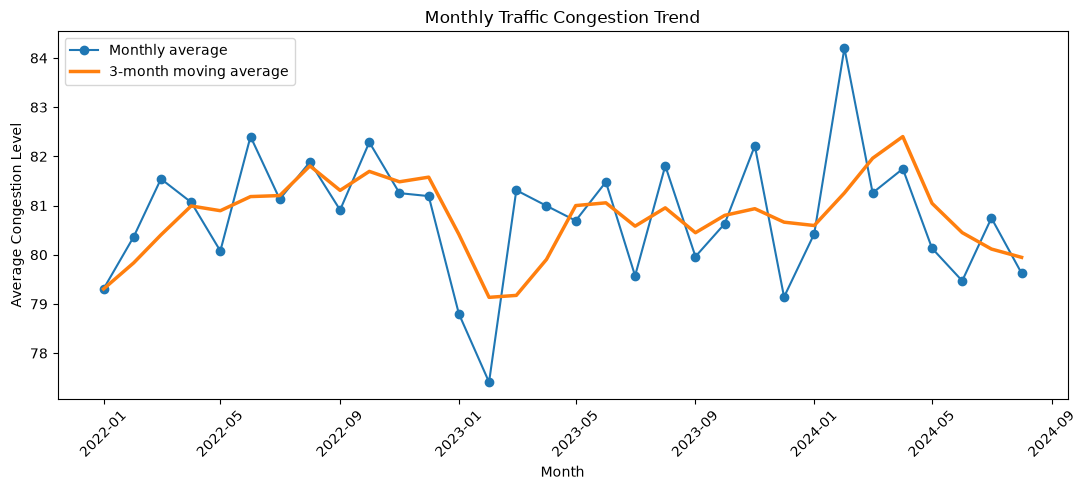

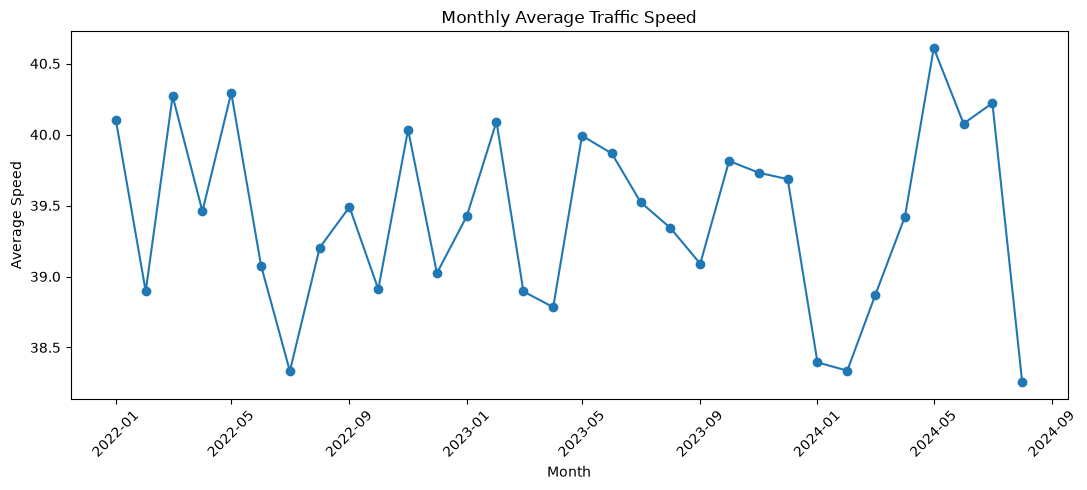

,observations,mean_volume,mean_speed,mean_congestion
is_weekend,,,,
False,6374,29297.17,39.43,80.89
True,2562,29083.98,39.49,80.64


,mean_congestion,mean_speed,mean_volume
date,,,
2022-09-01,80.91,39.49,29239.16
2022-10-01,82.29,38.91,30039.57
2022-11-01,81.25,40.03,29558.76
2022-12-01,81.19,39.02,29794.84
2023-01-01,78.80,39.42,28387.61
2023-02-01,77.41,40.09,28414.49
2023-03-01,81.31,38.89,29260.78
2023-04-01,80.99,38.78,29739.54
2023-05-01,80.69,39.99,28930.76


In [13]:
# Monthly traffic trends
df["date"] = pd.to_datetime(df["date"])

monthly = df.set_index("date").resample("MS").agg(
    mean_congestion=("congestion_level", "mean"),
    mean_speed=("average_speed", "mean"),
    mean_volume=("traffic_volume", "mean")
)

# Graph 1: Monthly congestion trend
plt.figure(figsize=(11, 5))
plt.plot(
    monthly.index,
    monthly["mean_congestion"],
    marker="o",
    label="Monthly average"
)
plt.plot(
    monthly.index,
    monthly["mean_congestion"].rolling(
        3, min_periods=1
    ).mean(),
    linewidth=2.5,
    label="3-month moving average"
)
plt.title("Monthly Traffic Congestion Trend")
plt.xlabel("Month")
plt.ylabel("Average Congestion Level")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Graph 2: Monthly average speed
plt.figure(figsize=(11, 5))
plt.plot(
    monthly.index,
    monthly["mean_speed"],
    marker="o"
)
plt.title("Monthly Average Traffic Speed")
plt.xlabel("Month")
plt.ylabel("Average Speed")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Retain the weekday/weekend comparison
display(df.groupby("is_weekend").agg(
    observations=("traffic_volume", "size"),
    mean_volume=("traffic_volume", "mean"),
    mean_speed=("average_speed", "mean"),
    mean_congestion=("congestion_level", "mean")
).round(2))

display(monthly.tail(24).round(2))

## 14. Group analysis and congestion drivers — Task 15

In [ ]:
display(df.groupby("weather_conditions").agg(
    observations=("congestion_level","size"),
    mean_congestion=("congestion_level","mean"),
    mean_speed=("average_speed","mean"),
    mean_volume=("traffic_volume","mean")
).sort_values("mean_congestion", ascending=False).round(2))
display(df.groupby("roadwork_and_construction_activity").agg(
    observations=("congestion_level","size"),
    mean_congestion=("congestion_level","mean"),
    mean_speed=("average_speed","mean"),
    mean_volume=("traffic_volume","mean")
).round(2))
display(df.groupby("area_name").agg(
    mean_signal_compliance=("traffic_signal_compliance","mean"),
    mean_parking_usage=("parking_usage","mean"),
    mean_pedestrian_cyclist_count=("pedestrian_and_cyclist_count","mean"),
    mean_public_transport_usage=("public_transport_usage","mean")
).round(2))

,observations,mean_congestion,mean_speed,mean_volume
weather_conditions,,,,
Windy,428,82.37,39.52,30163.22
Fog,959,81.61,39.47,29183.32
Clear,5426,80.72,39.47,29166.67
Rain,827,80.54,39.28,29558.70
Overcast,1296,80.30,39.43,29053.46


,observations,mean_congestion,mean_speed,mean_volume
roadwork_and_construction_activity,,,,
No,8054,80.82,39.50,29194.61
Yes,882,80.78,38.97,29614.44


,mean_signal_compliance,mean_parking_usage,mean_pedestrian_cyclist_count,mean_public_transport_usage
area_name,,,,
Electronic City,79.87,75.79,143.48,45.58
Hebbal,79.90,75.74,111.79,44.44
Indiranagar,80.05,75.54,110.34,44.92
Jayanagar,80.22,75.12,111.57,43.98
Koramangala,79.64,74.69,104.64,45.90
M.G. Road,79.94,74.53,109.45,45.44
Whitefield,79.98,75.60,120.94,44.59
Yeshwanthpur,80.00,74.64,131.44,46.13


## 15. Bottlenecks — Task 16

In [ ]:
bottlenecks = df.groupby(["area_name","road_intersection_name"]).agg(
    observations=("congestion_level","size"),
    mean_congestion=("congestion_level","mean"),
    mean_speed=("average_speed","mean"),
    mean_tti=("travel_time_index","mean"),
    mean_capacity_utilization=("road_capacity_utilization","mean"),
    mean_incidents=("incident_reports","mean")
).sort_values(["mean_congestion","mean_tti"], ascending=False)
display(bottlenecks.head(10).round(2))

observations  mean_congestion  mean_speed  \
area_name   road_intersection_name                                              
Koramangala Sony World Junction              684            94.13       35.98   
            Sarjapur Road                    680            93.85       36.15   
M.G. Road   Anil Kumble Circle               759            90.78       37.40   
            Trinity Circle                   742            90.37       37.68   
Indiranagar CMH Road                         860            88.18       38.86   
            100 Feet Road                    860            87.11       38.43   
Hebbal      Hebbal Flyover                   474            80.66       40.34   
            Ballari Road                     476            79.51       39.96   
Jayanagar   South End Circle                 593            77.28       39.44   
            Jayanagar 4th Block              580            76.71       40.15   

                                    mean_tti  mean_capacity_utilization  \
area_name   road_intersection_name                                        
Koramangala Sony World Junction         1.47                      97.46   
            Sarjapur Road               1.47                      97.39   
M.G. Road   Anil Kumble Circle          1.44                      96.61   
            Trinity Circle              1.44                      96.50   
Indiranagar CMH Road                    1.41                      95.85   
            100 Feet Road               1.40                      95.67   
Hebbal      Hebbal Flyover              1.37                      92.81   
            Ballari Road                1.36                      92.63   
Jayanagar   South End Circle            1.36                      91.50   
            Jayanagar 4th Block         1.35                      91.53   

                                    mean_incidents  
area_name   road_intersection_name                  
Koramangala Sony World Junction               1.81  
            Sarjapur Road                     1.88  
M.G. Road   Anil Kumble Circle                1.81  
            Trinity Circle                    1.92  
Indiranagar CMH Road                          1.75  
            100 Feet Road                     1.80  
Hebbal      Hebbal Flyover                    1.53  
            Ballari Road                      1.60  
Jayanagar   South End Circle                  1.52  
            Jayanagar 4th Block               1.45

## 16. Network efficiency — Task 17

In [ ]:
df["speed_per_volume_proxy"] = df["average_speed"] / df["traffic_volume"]
display(df.groupby(["area_name","road_intersection_name"]).agg(
    mean_speed_per_volume_proxy=("speed_per_volume_proxy","mean"),
    mean_speed=("average_speed","mean"),
    mean_volume=("traffic_volume","mean"),
    mean_congestion=("congestion_level","mean"),
    mean_capacity_utilization=("road_capacity_utilization","mean")
).sort_values("mean_speed_per_volume_proxy").round(6))

mean_speed_per_volume_proxy  \
area_name       road_intersection_name                                
Koramangala     Sony World Junction                        0.001065   
                Sarjapur Road                              0.001098   
M.G. Road       Anil Kumble Circle                         0.001291   
                Trinity Circle                             0.001299   
Indiranagar     CMH Road                                   0.001481   
                100 Feet Road                              0.001484   
Hebbal          Hebbal Flyover                             0.001895   
                Ballari Road                               0.001902   
Jayanagar       South End Circle                           0.001970   
                Jayanagar 4th Block                        0.001991   
Whitefield      ITPL Main Road                             0.002323   
                Marathahalli Bridge                        0.002549   
Yeshwanthpur    Yeshwanthpur Circle                        0.002799   
                Tumkur Road                                0.002821   
Electronic City Hosur Road                                 0.003199   
                Silk Board Junction                        0.003395   

                                        mean_speed   mean_volume  \
area_name       road_intersection_name                             
Koramangala     Sony World Junction      35.980025  41470.801170   
                Sarjapur Road            36.145719  40189.950000   
M.G. Road       Anil Kumble Circle       37.395406  35251.828722   
                Trinity Circle           37.678174  35350.137466   
Indiranagar     CMH Road                 38.860062  32611.924419   
                100 Feet Road            38.428621  31956.852326   
Hebbal          Hebbal Flyover           40.343881  26794.924051   
                Ballari Road             39.956644  26272.640756   
Jayanagar       South End Circle         39.438724  24704.119730   
                Jayanagar 4th Block      40.148526  24496.236207   
Whitefield      ITPL Main Road           41.972256  21866.037778   
                Marathahalli Bridge      42.295083  20772.953252   
Yeshwanthpur    Yeshwanthpur Circle      42.965323  19277.115282   
                Tumkur Road              43.945861  18574.490305   
Electronic City Hosur Road               43.991574  16557.223827   
                Silk Board Junction      43.329606  16134.534545   

                                        mean_congestion  \
area_name       road_intersection_name                    
Koramangala     Sony World Junction           94.125087   
                Sarjapur Road                 93.845163   
M.G. Road       Anil Kumble Circle            90.782145   
                Trinity Circle                90.372556   
Indiranagar     CMH Road                      88.176365   
                100 Feet Road                 87.107415   
Hebbal          Hebbal Flyover                80.662354   
                Ballari Road                  79.514551   
Jayanagar       South End Circle              77.277398   
                Jayanagar 4th Block           76.712995   
Whitefield      ITPL Main Road                71.101106   
                Marathahalli Bridge           67.182913   
Yeshwanthpur    Yeshwanthpur Circle           63.744162   
                Tumkur Road                   60.949415   
Electronic City Hosur Road                    55.203745   
                Silk Board Junction           53.699820   

                                        mean_capacity_utilization  
area_name       road_intersection_name                             
Koramangala     Sony World Junction                     97.462395  
                Sarjapur Road                           97.391909  
M.G. Road       Anil Kumble Circle                      96.609093  
                Trinity Circle                          96.498600  
Indiranagar     CMH Road                                95.848204

`speed / volume` is unit-dependent and should be called a proxy, not a validated network efficiency measure. Capacity utilization and congestion are more directly interpretable indicators in this dataset.

## 17. Expected traffic and deviation — Task 19

In [ ]:
df["day_name"] = df["date"].dt.day_name()
df["expected_volume"] = df.groupby(["day_name","month"])["traffic_volume"].transform("mean")
df["volume_gap"] = df["traffic_volume"] - df["expected_volume"]
df["expected_congestion"] = df.groupby(["day_name","month"])["congestion_level"].transform("mean")
df["congestion_gap"] = df["congestion_level"] - df["expected_congestion"]
display(df.reindex(df["volume_gap"].abs().sort_values(ascending=False).index)[
    ["date","area_name","road_intersection_name","traffic_volume","expected_volume","volume_gap","congestion_gap"]
].head(20))

,date,area_name,road_intersection_name,traffic_volume,expected_volume,volume_gap,congestion_gap
2002,2022-08-01,Koramangala,Sarjapur Road,71610,29566.617647,42043.382353,18.483216
4010,2023-03-05,Koramangala,Sarjapur Road,69494,28218.777778,41275.222222,21.245659
6072,2023-10-11,Koramangala,Sony World Junction,72039,31157.378788,40881.621212,18.481611
2314,2022-09-03,Koramangala,Sony World Junction,69407,28978.493827,40428.506173,23.934272
8898,2024-08-06,Koramangala,Sony World Junction,69158,29550.657407,39607.342593,17.792384
287,2022-02-01,Koramangala,Sony World Junction,67693,28097.982759,39595.017241,20.941386
4442,2023-04-22,Koramangala,Sarjapur Road,67271,27793.666667,39477.333333,21.099319
1653,2022-06-26,Koramangala,Sony World Junction,69874,30637.500000,39236.500000,17.040889
587,2022-03-04,Koramangala,Sarjapur Road,69293,30106.333333,39186.666667,16.525115
5339,2023-07-28,Koramangala,Sony World Junction,65535,26665.598425,38869.401575,23.170142


This baseline is a descriptive benchmark grouped by weekday name and calendar month. It is not a causal normal-traffic model and can be affected by changing road coverage and seasonal patterns.

## 18. High-risk congestion screening — Task 20

In [ ]:
cong_thr = df["congestion_level"].quantile(.75)
tti_thr = df["travel_time_index"].quantile(.75)
df["risk_flag"] = ((df["congestion_level"] >= cong_thr) & (df["travel_time_index"] >= tti_thr)).astype(int)
risk_summary = df.groupby(["area_name","road_intersection_name"]).agg(
    risk_observations=("risk_flag","sum"),
    risk_share=("risk_flag","mean"),
    mean_congestion=("congestion_level","mean"),
    mean_tti=("travel_time_index","mean")
).sort_values(["risk_share","risk_observations"], ascending=False)
display(risk_summary.head(15).round(3))
print("Risk rule thresholds:", {"congestion_q75":cong_thr, "travel_time_index_q75":tti_thr})

risk_observations  risk_share  \
area_name       road_intersection_name                                  
Koramangala     Sony World Junction                   527       0.770   
                Sarjapur Road                         503       0.740   
M.G. Road       Trinity Circle                        475       0.640   
                Anil Kumble Circle                    475       0.626   
Indiranagar     CMH Road                              511       0.594   
                100 Feet Road                         492       0.572   
Hebbal          Hebbal Flyover                        187       0.395   
                Ballari Road                          174       0.366   
Jayanagar       South End Circle                      169       0.285   
                Jayanagar 4th Block                   155       0.267   
Whitefield      ITPL Main Road                         82       0.182   
                Marathahalli Bridge                    64       0.130   
Yeshwanthpur    Yeshwanthpur Circle                    29       0.078   
                Tumkur Road                            24       0.066   
Electronic City Silk Board Junction                     9       0.033   

                                        mean_congestion  mean_tti  
area_name       road_intersection_name                             
Koramangala     Sony World Junction              94.125     1.470  
                Sarjapur Road                    93.845     1.468  
M.G. Road       Trinity Circle                   90.373     1.437  
                Anil Kumble Circle               90.782     1.444  
Indiranagar     CMH Road                         88.176     1.408  
                100 Feet Road                    87.107     1.396  
Hebbal          Hebbal Flyover                   80.662     1.373  
                Ballari Road                     79.515     1.363  
Jayanagar       South End Circle                 77.277     1.359  
                Jayanagar 4th Block              76.713     1.355  
Whitefield      ITPL Main Road                   71.101     1.301  
                Marathahalli Bridge              67.183     1.287  
Yeshwanthpur    Yeshwanthpur Circle              63.744     1.273  
                Tumkur Road                      60.949     1.255  
Electronic City Silk Board Junction              53.700     1.227

Risk rule thresholds: {'congestion_q75': np.float64(100.0), 'travel_time_index_q75': np.float64(1.5)}


This is a transparent screening rule, not a trained predictive model. Historical validation here means reviewing whether flagged records coincide with high congestion/TTI; no independent incident outcome label is supplied.

## 19. Breakdown and recovery — Task 21

In [ ]:
breakdowns = df.loc[(df["volume_gap"] > df["volume_gap"].quantile(.95)) |
                    (df["congestion_gap"] > df["congestion_gap"].quantile(.95))].copy()
display(breakdowns[["date","area_name","road_intersection_name","traffic_volume","volume_gap","congestion_level","congestion_gap","incident_reports","weather_conditions","roadwork_and_construction_activity"]].head(30))

,date,area_name,road_intersection_name,traffic_volume,volume_gap,congestion_level,congestion_gap,incident_reports,weather_conditions,roadwork_and_construction_activity
1389,2022-05-29,Electronic City,Hosur Road,30788,3516.369369,100.0,23.586138,2,Overcast,No
70,2022-01-07,Hebbal,Ballari Road,42022,13379.226087,100.0,22.386011,5,Clear,No
1489,2022-06-09,Hebbal,Ballari Road,43017,13672.992000,100.0,21.705981,0,Windy,No
1697,2022-06-30,Hebbal,Ballari Road,34346,5001.992000,100.0,21.705981,0,Clear,No
1853,2022-07-16,Hebbal,Ballari Road,31566,3518.474453,100.0,22.454878,2,Fog,No
2310,2022-09-02,Hebbal,Ballari Road,32683,5094.461538,100.0,21.782892,2,Clear,No
2377,2022-09-10,Hebbal,Ballari Road,39751,10772.506173,100.0,23.934272,2,Clear,No
3262,2022-12-12,Hebbal,Ballari Road,39083,11971.679487,100.0,23.133714,1,Rain,No
3543,2023-01-13,Hebbal,Ballari Road,31631,2988.226087,100.0,22.386011,3,Clear,No
5139,2023-07-07,Hebbal,Ballari Road,36693,10027.401575,100.0,23.170142,1,Rain,No


Potential situational context can be compared using incidents, weather, and roadwork flags. The dataset does not include incident timestamps, incident types, or post-event recovery sequences, so it cannot conclusively distinguish structural causes from situational causes or calculate recovery duration.

## 20. Demand versus capacity — Task 22

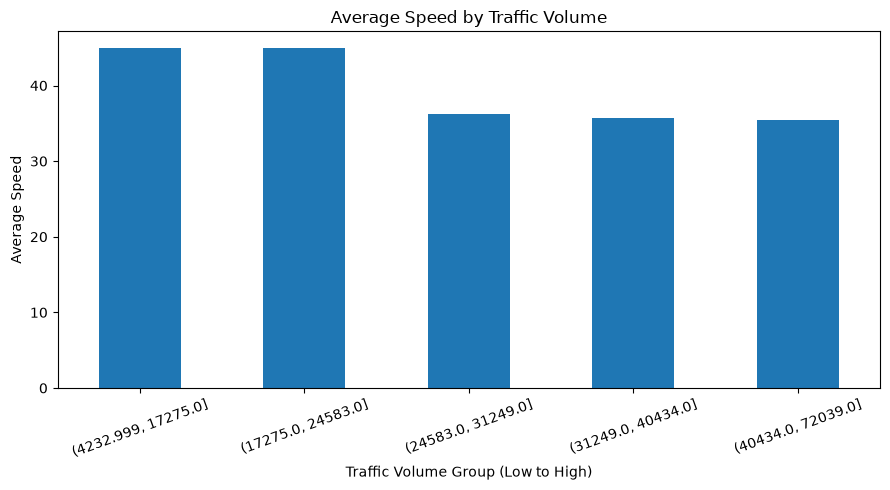

In [ ]:
# Task 22: Average Speed by Traffic Volume

df["traffic_volume_numeric"] = pd.to_numeric(
    df["traffic_volume"], errors="coerce"
)

df["volume_group_plot"] = pd.qcut(
    df["traffic_volume_numeric"],
    q=5,
    duplicates="drop"
)

speed_summary = df.groupby(
    "volume_group_plot",
    observed=True
)["average_speed"].mean()

plt.figure(figsize=(9, 5))
speed_summary.plot(kind="bar", rot=20)

plt.title("Average Speed by Traffic Volume")
plt.xlabel("Traffic Volume Group (Low to High)")
plt.ylabel("Average Speed")

plt.tight_layout()
plt.show()

## 21. Interactive mobility dashboard — Task 23

A separate "Bengaluru_Traffic_Dashboard.py" file is provided for the interactive mobility dashboard.

How to launch the dashboard:

1. Open the project folder in VS Code.

2. Open the terminal in VS Code.

3. Install the required libraries (if not already installed):
   
   python -m pip install streamlit pandas plotly

4. Run the dashboard using:
   
   python -m streamlit run Bengaluru_Traffic_Dashboard.py

5. Streamlit will open the dashboard in your web browser. If it does not open automatically, copy the local URL displayed in the terminal and open it in your browser.

Dashboard features: The dashboard provides interactive filters for area, road/intersection, date range, weather, and risk flag. It displays traffic volume, average speed, congestion, travel-time index, and risk summaries.

## 22. Scenario simulation — Task 24

In [ ]:
# Illustrative 15% traffic-volume reduction scenario
# This is a scenario, not a prediction of actual congestion changes.

import numpy as np
import pandas as pd

sim = df.copy()

# Ensure the required columns are numeric
traffic = pd.to_numeric(sim["traffic_volume"], errors="coerce")
congestion = pd.to_numeric(sim["congestion_level"], errors="coerce")

# Identify records in the highest-congestion quartile
target = congestion >= congestion.quantile(0.75)

# Create the simulated column as floating-point values
sim["simulated_traffic_volume"] = np.where(
    target,
    traffic.astype(float) * 0.85,
    traffic.astype(float)
)

# Compare baseline and scenario
scenario = pd.DataFrame({
    "metric": [
        "Mean traffic volume (all records)",
        "Mean observed congestion (unchanged)",
        "Target records volume reduction (%)"
    ],
    "baseline": [
        traffic.mean(),
        congestion.mean(),
        0.0
    ],
    "scenario": [
        sim["simulated_traffic_volume"].mean(),
        congestion.mean(),
        15.0 if target.any() else 0.0
    ]
})

display(scenario.round(2))

print(
    "Note: This is an illustrative volume-reduction scenario. "
    "It does not predict congestion improvement because no validated "
    "model linking traffic volume to congestion is available."
)

,metric,baseline,scenario
0,Mean traffic volume (all records),29236.05,26541.51
1,Mean observed congestion (unchanged),80.82,80.82
2,Target records volume reduction (%),0.00,15.00


Note: This is an illustrative volume-reduction scenario. It does not predict congestion improvement because no validated model linking traffic volume to congestion is available.


## 23. Structural weaknesses, roadmap, and monitoring — Tasks 25–27

Use measured results to prioritize the highest-congestion road/area profiles and observations combining high congestion with high travel-time index. Candidate interventions to evaluate with transport authorities include signal coordination, public-transport integration, parking management, demand management, incident response, and smart traffic monitoring. Road widening should not be recommended solely from this dataset; engineering capacity, right-of-way, cost, and induced-demand evidence are not provided.

**Monitoring cadence**
- Daily: data coverage, speed, volume, congestion, incidents, missing records.
- Monthly: recurring high-risk road/area profiles, weather/roadwork comparisons, capacity utilization.
- Quarterly/yearly: compare post-intervention indicators with a defined baseline and control for coverage changes; document infrastructure costs and unintended effects.

## 25. Extended validation, reliability, scenario, and evidence register — closes Tasks 4, 6, 8, 10–11, 14–17, 19–22, 24–27

This section adds explicit before/after validation, coverage checks, reliability KPIs, grouped baselines, transparent risk review, evidence-backed recommendations, and a monitoring specification. It does **not** manufacture unavailable hourly, road-type, demographic, or recovery-time information.

### 25.1 Before/after quality and observation coverage (Tasks 4 and 6)


In [ ]:
# Compare source and prepared analytical view, including row counts and key summary statistics.
raw_for_compare = df_raw.copy()
raw_for_compare.columns = [c.strip().lower().replace("/", "_").replace(" ", "_") for c in raw_for_compare.columns]
raw_for_compare["date"] = pd.to_datetime(raw_for_compare["date"], errors="coerce")
compare_rows = []
for label, frame in [("Raw source", raw_for_compare), ("Prepared analysis", df)]:
    compare_rows.append({
        "stage": label, "rows": len(frame), "columns": len(frame.columns),
        "missing_cells": int(frame.isna().sum().sum()),
        "exact_duplicate_rows": int(frame.duplicated().sum()),
        "mean_volume": frame["traffic_volume"].mean(),
        "mean_speed": frame["average_speed"].mean(),
        "mean_congestion": frame["congestion_level"].mean(),
        "mean_capacity_utilization": frame["road_capacity_utilization"].mean()
    })
display(pd.DataFrame(compare_rows).round(3))

coverage = df.groupby("date").size().rename("observations_per_date")
expected_dates = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
coverage_summary = pd.Series({
    "first_date": str(df["date"].min().date()),
    "last_date": str(df["date"].max().date()),
    "calendar_days_in_span": len(expected_dates),
    "dates_with_observations": int(coverage.size),
    "dates_with_no_observations": int(len(expected_dates.difference(coverage.index))),
    "minimum_observations_per_date": int(coverage.min()),
    "maximum_observations_per_date": int(coverage.max()),
    "duplicate_date-area-road_keys": int(df.duplicated(["date","area_name","road_intersection_name"]).sum())
})
display(coverage_summary.to_frame("value"))
display(coverage.value_counts().sort_index().rename_axis("observations_per_date").to_frame("number_of_dates"))


,stage,rows,columns,missing_cells,exact_duplicate_rows,mean_volume,mean_speed,mean_congestion,mean_capacity_utilization
0,Raw source,8936,16,0,0,29236.048,39.447,80.818,92.029
1,Prepared analysis,8936,36,32,0,29236.048,39.447,80.818,92.029


,value
first_date,2022-01-01
last_date,2024-08-09
calendar_days_in_span,952
dates_with_observations,952
dates_with_no_observations,0
minimum_observations_per_date,4
maximum_observations_per_date,15
duplicate_date-area-road_keys,0


,number_of_dates
observations_per_date,
4,4
5,11
6,23
7,95
8,152
9,213
10,199
11,156
12,71


### 25.2 Systematic consistency review (Task 8)

Correlations are screening evidence, not proof of causation. The tables below identify combinations worth investigating without labelling them automatically as errors.


In [ ]:
# Compare indicators against data-wide quartiles and flag potential mismatches for manual review.
vol_hi = df["traffic_volume"].quantile(.75)
speed_lo = df["average_speed"].quantile(.25)
cong_hi = df["congestion_level"].quantile(.75)
util_hi = df["road_capacity_utilization"].quantile(.75)
df["consistency_review_flag"] = (
    ((df["traffic_volume"] >= vol_hi) & (df["average_speed"] >= df["average_speed"].quantile(.75)) & (df["congestion_level"] >= cong_hi)) |
    ((df["traffic_volume"] <= df["traffic_volume"].quantile(.25)) & (df["average_speed"] <= speed_lo) & (df["congestion_level"] <= df["congestion_level"].quantile(.25))) |
    ((df["road_capacity_utilization"] >= util_hi) & (df["congestion_level"] <= df["congestion_level"].quantile(.25)))
)
print("Potential consistency-review records:", int(df["consistency_review_flag"].sum()))
display(df.loc[df["consistency_review_flag"], [
    "date","area_name","road_intersection_name","traffic_volume","average_speed",
    "congestion_level","road_capacity_utilization","incident_reports"
]].head(25))


Potential consistency-review records: 595


,date,area_name,road_intersection_name,traffic_volume,average_speed,congestion_level,road_capacity_utilization,incident_reports
558,2022-03-01,Electronic City,Hosur Road,12665,31.668520,35.154598,68.033542,2
688,2022-03-14,Electronic City,Hosur Road,14352,31.684917,52.830532,71.858741,1
772,2022-03-23,Electronic City,Hosur Road,20339,44.398455,63.193336,100.000000,0
1097,2022-04-27,Electronic City,Hosur Road,9882,23.188248,34.140087,44.861110,0
1126,2022-04-30,Electronic City,Hosur Road,20626,41.896035,59.241960,100.000000,1
1316,2022-05-21,Electronic City,Hosur Road,10947,31.027858,33.541974,57.020426,1
1841,2022-07-15,Electronic City,Hosur Road,5889,29.952867,14.002650,25.575075,2
2852,2022-10-30,Electronic City,Hosur Road,19289,52.066685,57.311576,100.000000,2
2981,2022-11-12,Electronic City,Hosur Road,19129,36.061202,60.431083,100.000000,0
3267,2022-12-13,Electronic City,Hosur Road,10566,29.527620,29.078415,52.850994,2


### 25.3 Reliability and persistence KPIs (Tasks 10–11, 17)

Because observations are daily and not hourly, these KPIs describe day-to-day records. They are proxies and must not be described as travel-time reliability from individual journeys.


In [ ]:
# Consecutive-observation measures are calculated within each road/intersection series.
series_keys = ["area_name", "road_intersection_name"]
df = df.sort_values(series_keys + ["date"]).copy()
df["congestion_change_abs"] = df.groupby(series_keys)["congestion_level"].diff().abs()
df["speed_change_abs"] = df.groupby(series_keys)["average_speed"].diff().abs()
df["congested_observation"] = (df["congestion_level"] >= df["congestion_level"].quantile(.75)).astype(int)
df["congestion_run_group"] = (df.groupby(series_keys)["congested_observation"].diff().fillna(0).ne(0)).groupby(
    [df["area_name"], df["road_intersection_name"]]).cumsum()
run_lengths = (df.loc[df["congested_observation"].eq(1)]
               .groupby(series_keys + ["congestion_run_group"]).size().rename("congested_run_length"))
reliability_profile = df.groupby(series_keys).agg(
    observations=("date","size"),
    mean_congestion=("congestion_level","mean"),
    congestion_sd=("congestion_level","std"),
    mean_speed=("average_speed","mean"),
    speed_sd=("average_speed","std"),
    mean_abs_daily_congestion_change=("congestion_change_abs","mean"),
    mean_abs_daily_speed_change=("speed_change_abs","mean"),
    high_congestion_share=("congested_observation","mean"),
    mean_capacity_utilization=("road_capacity_utilization","mean"),
    high_capacity_share=("high_capacity_flag","mean")
).sort_values(["high_congestion_share","mean_congestion"], ascending=False)
display(reliability_profile.head(20).round(3))
if len(run_lengths):
    display(run_lengths.describe().to_frame("congested_run_length_days").round(2))
else:
    print("No high-congestion runs available for duration summary.")


observations  mean_congestion  \
area_name       road_intersection_name                                  
Koramangala     Sony World Junction              684           94.125   
                Sarjapur Road                    680           93.845   
M.G. Road       Trinity Circle                   742           90.373   
                Anil Kumble Circle               759           90.782   
Indiranagar     CMH Road                         860           88.176   
                100 Feet Road                    860           87.107   
Hebbal          Hebbal Flyover                   474           80.662   
                Ballari Road                     476           79.515   
Jayanagar       South End Circle                 593           77.277   
                Jayanagar 4th Block              580           76.713   
Whitefield      ITPL Main Road                   450           71.101   
                Marathahalli Bridge              492           67.183   
Yeshwanthpur    Yeshwanthpur Circle              373           63.744   
                Tumkur Road                      361           60.949   
Electronic City Silk Board Junction              275           53.700   
                Hosur Road                       277           55.204   

                                        congestion_sd  mean_speed  speed_sd  \
area_name       road_intersection_name                                        
Koramangala     Sony World Junction            15.068      35.980     9.719   
                Sarjapur Road                  15.016      36.146     9.775   
M.G. Road       Trinity Circle                 17.594      37.678     9.935   
                Anil Kumble Circle             16.838      37.395     9.775   
Indiranagar     CMH Road                       19.155      38.860    10.781   
                100 Feet Road                  19.611      38.429    10.998   
Hebbal          Hebbal Flyover                 23.439      40.344    10.696   
                Ballari Road                   23.121      39.957    10.738   
Jayanagar       South End Circle               23.039      39.439    10.581   
                Jayanagar 4th Block            22.934      40.149    10.675   
Whitefield      ITPL Main Road                 23.066      41.972    10.916   
                Marathahalli Bridge            24.298      42.295    10.387   
Yeshwanthpur    Yeshwanthpur Circle            24.028      42.965    11.024   
                Tumkur Road                    22.212      43.946    10.534   
Electronic City Silk Board Junction            22.403      43.330    10.778   
                Hosur Road                     20.118      43.992    10.300   

                                        mean_abs_daily_congestion_change  \
area_name       road_intersection_name                                     
Koramangala     Sony World Junction                               10.266   
                Sarjapur Road                                     10.134   
M.G. Road       Trinity Circle                                    15.695   
                Anil Kumble Circle                                14.471   
Indiranagar     CMH Road                                          17.728   
                100 Feet Road                                     18.476   
Hebbal          Hebbal Flyover                                    24.337   
                Ballari Road                                      25.863   
Jayanagar       South End Circle                                  25.522   
                Jayanagar 4th Block                               24.922   
Whitefield      ITPL Main Road                                    26.892   
                Marathahalli Bridge                               28.404   
Yeshwanthpur    Yeshwanthpur Circle                               28.839   
                Tumkur Road                                       24.459   
Electronic City Silk Board Junction                               26.131   
          

,congested_run_length_days
count,1683.00
mean,2.31
std,2.09
min,1.00
25%,1.00
50%,1.00
75%,3.00
max,22.00


### 25.4 Road-aware expected baseline and historical risk review (Tasks 19–20)


In [ ]:
# Baseline compares each observation with the same road/intersection, weekday and month where enough data exists.
baseline_keys = ["area_name", "road_intersection_name", "day_name", "month"]
baseline = df.groupby(baseline_keys).agg(
    baseline_volume=("traffic_volume","mean"),
    baseline_congestion=("congestion_level","mean"),
    baseline_speed=("average_speed","mean"),
    baseline_n=("date","size")
).reset_index()
df = df.merge(baseline, on=baseline_keys, how="left", validate="many_to_one")
df["volume_deviation_from_baseline"] = df["traffic_volume"] - df["baseline_volume"]
df["congestion_deviation_from_baseline"] = df["congestion_level"] - df["baseline_congestion"]
display(df.sort_values("congestion_deviation_from_baseline", ascending=False)[
    ["date","area_name","road_intersection_name","traffic_volume","baseline_volume",
     "congestion_level","baseline_congestion","baseline_n"]
].head(20).round(2))

# Historical review of the transparent screening rule: report how often flagged observations coincide with incidents/roadwork.
risk_validation = df.groupby("risk_flag").agg(
    observations=("risk_flag","size"),
    mean_congestion=("congestion_level","mean"),
    mean_tti=("travel_time_index","mean"),
    incident_rate=("incident_reports",lambda s: (s > 0).mean()),
    roadwork_rate=("roadwork_and_construction_activity",lambda s: s.astype(str).str.lower().isin(["yes","true","1"]).mean()),
    mean_speed=("average_speed","mean")
)
display(risk_validation.round(3))
print("Important: this is descriptive historical review, not out-of-sample validation of a predictive model.")


C:\Users\Hp\AppData\Local\Temp\ipykernel_31576\1381350239.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(20).round(2))


,date,area_name,road_intersection_name,traffic_volume,baseline_volume,congestion_level,baseline_congestion,baseline_n
8635,2022-06-15,Yeshwanthpur,Yeshwanthpur Circle,33081,13133.75,100.00,37.98,4
548,2024-07-30,Electronic City,Silk Board Junction,28018,14552.00,100.00,45.67,5
486,2024-01-03,Electronic City,Silk Board Junction,28182,13081.38,99.80,46.57,8
498,2024-02-12,Electronic City,Silk Board Junction,28358,12698.25,96.09,42.86,4
8634,2022-06-14,Yeshwanthpur,Yeshwanthpur Circle,27017,14662.40,98.77,48.17,5
376,2022-12-06,Electronic City,Silk Board Junction,29268,15525.00,100.00,49.47,5
8898,2024-04-15,Yeshwanthpur,Yeshwanthpur Circle,38877,17658.00,100.00,49.89,4
7919,2023-01-30,Whitefield,Marathahalli Bridge,32122,14812.00,100.00,50.06,9
7264,2022-01-09,Whitefield,ITPL Main Road,34188,17001.50,100.00,50.12,4
503,2024-02-22,Electronic City,Silk Board Junction,33472,16477.88,100.00,50.65,8


,observations,mean_congestion,mean_tti,incident_rate,roadwork_rate,mean_speed
risk_flag,,,,,,
0,5052,66.071,1.28,0.632,0.095,42.381
1,3884,100.000,1.50,0.861,0.104,35.632


Important: this is descriptive historical review, not out-of-sample validation of a predictive model.


### 25.5 Demand/capacity, scenario limits, structural weaknesses and monitoring (Tasks 22, 24–27)


In [ ]:
# Explicit evidence register: top road/area profiles, plus measured indicators to track.
evidence_register = bottlenecks.reset_index().head(10).copy()
evidence_register["interpretation"] = "Priority for field review based on observed congestion/TTI; not proof of a specific cause"
display(evidence_register.round(2))

# Transparent scenario: arithmetic change in volume only; observed congestion is NOT changed by an unvalidated formula.
scenario_rows = []
for reduction in [0.05, 0.10, 0.15, 0.20]:
    adjusted_volume = df["traffic_volume"].astype(float).copy()
    target = df["congestion_level"] >= df["congestion_level"].quantile(.75)
    adjusted_volume.loc[target] = adjusted_volume.loc[target] * (1 - reduction)
    scenario_rows.append({
        "target": "highest-congestion quartile",
        "assumed_volume_reduction_pct": reduction * 100,
        "mean_volume_before": df["traffic_volume"].mean(),
        "mean_volume_after_arithmetic_only": adjusted_volume.mean(),
        "mean_congestion_observed_unchanged": df["congestion_level"].mean(),
        "predicted_congestion_change": "Not estimated — requires validated response model"
    })
display(pd.DataFrame(scenario_rows).round(2))

monitoring_framework = pd.DataFrame([
    ["Daily", "Mean/90th percentile congestion; mean speed; high-congestion share", "Area and road/intersection", "Investigate sustained deterioration"],
    ["Daily", "Capacity utilization and incident counts", "Area and road/intersection", "Check near-capacity and incident-linked records"],
    ["Weekly", "Congestion variability and consecutive high-congestion days", "Road/intersection", "Prioritize field observation and signal review"],
    ["Monthly", "Weather/roadwork-stratified congestion and speed", "Comparable groups only", "Review confounding and sample sizes"],
    ["Quarterly", "Baseline deviation, risk-flag precision and data completeness", "Network and priority roads", "Recalibrate thresholds; document changes"],
    ["Before/after intervention", "Comparable dates, volume, speed, congestion and capacity utilization", "Treatment road and comparison group", "Avoid causal claims without a credible comparison design"],
], columns=["cadence","indicators","breakdown","action"])
display(monitoring_framework)

structural_weaknesses = pd.DataFrame([
    ["No time-of-day field", "Cannot test AM/PM peaks or hourly signal timing", "Collect timestamp/hour and direction-level counts"],
    ["No explicit road type, zone or coordinates", "Cannot isolate road-class effects or map network connectivity", "Add road classification, GIS coordinates and network links"],
    ["No population or traveller demographics", "Area congestion alone cannot establish mobility inequity", "Add privacy-safe exposure, accessibility and demographic indicators"],
    ["Daily aggregated observations", "Cannot estimate journey-level travel-time reliability or precise breakdown/recovery duration", "Collect higher-frequency probe/travel-time data and incident start/end times"],
    ["No intervention/control design", "Scenario arithmetic cannot predict congestion reduction causally", "Run calibrated model or staged pilot with comparison corridors"],
], columns=["data_or_design_gap","consequence","recommended_action"])
display(structural_weaknesses)



,area_name,road_intersection_name,observations,mean_congestion,mean_speed,mean_tti,mean_capacity_utilization,mean_incidents,interpretation
0,Koramangala,Sony World Junction,684,94.13,35.98,1.47,97.46,1.81,Priority for field review based on observed co...
1,Koramangala,Sarjapur Road,680,93.85,36.15,1.47,97.39,1.88,Priority for field review based on observed co...
2,M.G. Road,Anil Kumble Circle,759,90.78,37.40,1.44,96.61,1.81,Priority for field review based on observed co...
3,M.G. Road,Trinity Circle,742,90.37,37.68,1.44,96.50,1.92,Priority for field review based on observed co...
4,Indiranagar,CMH Road,860,88.18,38.86,1.41,95.85,1.75,Priority for field review based on observed co...
5,Indiranagar,100 Feet Road,860,87.11,38.43,1.40,95.67,1.80,Priority for field review based on observed co...
6,Hebbal,Hebbal Flyover,474,80.66,40.34,1.37,92.81,1.53,Priority for field review based on observed co...
7,Hebbal,Ballari Road,476,79.51,39.96,1.36,92.63,1.60,Priority for field review based on observed co...
8,Jayanagar,South End Circle,593,77.28,39.44,1.36,91.50,1.52,Priority for field review based on observed co...
9,Jayanagar,Jayanagar 4th Block,580,76.71,40.15,1.35,91.53,1.45,Priority for field review based on observed co...


,target,assumed_volume_reduction_pct,mean_volume_before,mean_volume_after_arithmetic_only,mean_congestion_observed_unchanged,predicted_congestion_change
0,highest-congestion quartile,5.0,29236.05,28337.87,80.82,Not estimated — requires validated response model
1,highest-congestion quartile,10.0,29236.05,27439.69,80.82,Not estimated — requires validated response model
2,highest-congestion quartile,15.0,29236.05,26541.51,80.82,Not estimated — requires validated response model
3,highest-congestion quartile,20.0,29236.05,25643.33,80.82,Not estimated — requires validated response model


,cadence,indicators,breakdown,action
0,Daily,Mean/90th percentile congestion; mean speed; h...,Area and road/intersection,Investigate sustained deterioration
1,Daily,Capacity utilization and incident counts,Area and road/intersection,Check near-capacity and incident-linked records
2,Weekly,Congestion variability and consecutive high-co...,Road/intersection,Prioritize field observation and signal review
3,Monthly,Weather/roadwork-stratified congestion and speed,Comparable groups only,Review confounding and sample sizes
4,Quarterly,"Baseline deviation, risk-flag precision and da...",Network and priority roads,Recalibrate thresholds; document changes
5,Before/after intervention,"Comparable dates, volume, speed, congestion an...",Treatment road and comparison group,Avoid causal claims without a credible compari...


,data_or_design_gap,consequence,recommended_action
0,No time-of-day field,Cannot test AM/PM peaks or hourly signal timing,Collect timestamp/hour and direction-level counts
1,"No explicit road type, zone or coordinates",Cannot isolate road-class effects or map netwo...,"Add road classification, GIS coordinates and n..."
2,No population or traveller demographics,Area congestion alone cannot establish mobilit...,"Add privacy-safe exposure, accessibility and d..."
3,Daily aggregated observations,Cannot estimate journey-level travel-time reli...,Collect higher-frequency probe/travel-time dat...
4,No intervention/control design,Scenario arithmetic cannot predict congestion ...,Run calibrated model or staged pilot with comp...


## 24. Executive summary — Task 28

In [ ]:
area_summary = df.groupby("area_name").agg(
    observations=("congestion_level","size"),
    mean_congestion=("congestion_level","mean"),
    mean_speed=("average_speed","mean"),
    mean_tti=("travel_time_index","mean"),
    mean_capacity_utilization=("road_capacity_utilization","mean")
).sort_values("mean_congestion", ascending=False)
road_summary = df.groupby("road_intersection_name").agg(
    mean_congestion=("congestion_level","mean"),
    mean_speed=("average_speed","mean"),
    mean_tti=("travel_time_index","mean")
).sort_values("mean_congestion", ascending=False)
print("Executive summary evidence")
print("Overall mean congestion:", round(df["congestion_level"].mean(),2))
print("Overall mean speed:", round(df["average_speed"].mean(),2))
print("Overall mean travel-time index:", round(df["travel_time_index"].mean(),3))
print("Highest mean congestion areas:", area_summary.head(3).round(2).to_dict("index"))
print("Highest mean congestion roads:", road_summary.head(3).round(2).to_dict("index"))
print("Data coverage:", df["date"].min().date(), "to", df["date"].max().date())

Executive summary evidence
Overall mean congestion: 80.82
Overall mean speed: 39.45
Overall mean travel-time index: 1.376
Highest mean congestion areas: {'Koramangala': {'observations': 1364, 'mean_congestion': 93.99, 'mean_speed': 36.06, 'mean_tti': 1.47, 'mean_capacity_utilization': 97.43}, 'M.G. Road': {'observations': 1501, 'mean_congestion': 90.58, 'mean_speed': 37.54, 'mean_tti': 1.44, 'mean_capacity_utilization': 96.55}, 'Indiranagar': {'observations': 1720, 'mean_congestion': 87.64, 'mean_speed': 38.64, 'mean_tti': 1.4, 'mean_capacity_utilization': 95.76}}
Highest mean congestion roads: {'Sony World Junction': {'mean_congestion': 94.13, 'mean_speed': 35.98, 'mean_tti': 1.47}, 'Sarjapur Road': {'mean_congestion': 93.85, 'mean_speed': 36.15, 'mean_tti': 1.47}, 'Anil Kumble Circle': {'mean_congestion': 90.78, 'mean_speed': 37.4, 'mean_tti': 1.44}}
Data coverage: 2022-01-01 to 2024-08-09
